# Baseline — TF-IDF + Cosine Similarity

Classifica pares de produtos **sem nenhuma normalização por LLM**, usando apenas similaridade de texto sobre os títulos brutos.

Serve como linha de base para comparação com o pipeline `classifier_api.ipynb`.

| Baseline | Descrição |
|---|---|
| **tfidf_word** | TF-IDF por token (word-level) + cosine similarity |
| **tfidf_char** | TF-IDF por n-grama de caractere (3-4) + cosine similarity |

**Saída:** `dados/baseline_predictions.csv`

## Setup

In [1]:
import re
import unicodedata
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

PAIRS_CSV   = "dados/pairs_normalized.csv"
OUTPUT_CSV  = "dados/baseline_predictions.csv"
OUTPUT_JSON = "output/baseline_metrics.json"

Path("output").mkdir(parents=True, exist_ok=True)

## 1 — Carrega os pares rotulados

In [2]:
pairs_path = Path(PAIRS_CSV).resolve()
if not pairs_path.is_file():
    raise FileNotFoundError(
        f"CSV não encontrado: {pairs_path}.\n"
        "Execute classifier_api.ipynb (Passo 6) antes."
    )

df = pd.read_csv(pairs_path, dtype=str, encoding="utf-8-sig")
df["label"] = df["label"].str.strip().astype(int)

print(f"Pares carregados : {len(df)}")
print(f"Positivos (label=1): {df['label'].sum()}")
print(f"Negativos (label=0): {(df['label'] == 0).sum()}")
df[["title_a", "title_b", "label"]].head(5)

Pares carregados : 1200
Positivos (label=1): 30
Negativos (label=0): 1170


,title_a,title_b,label
0,Pulseira Casio Original Prata Gshock Dw5600e,Relógio Bvulgari,0
1,Trimpot 3386f De 500k Uma Volta Lote Com 25 Peças,Potenciometro Do A16o A190,0
2,Relógio De Parede Para Cozinha Talher Colher P...,Relógio Parede Personalizado Lata Pokemon,0
3,Mesa Em Madeira Rústica-pubs-bar- Johnnie Walk...,Frete Grátis | Cerveja 55 Sem Glúten | 18 Lata...,0
4,Cadeirinha Reclinável Preta Maestro Bebê 0 À 2...,Chicco - Xpace - Cadeirinha P/ Auto - Excelent...,0


## 2 — Pré-processamento leve (sem LLM)

Apenas lowercase + remoção de acentos + colapso de espaços.
Nenhuma regra de domínio — é isso que torna isso um baseline.

In [3]:
def simple_clean(text: str) -> str:
    text = unicodedata.normalize("NFD", str(text).lower())
    text = "".join(c for c in text if unicodedata.category(c) != "Mn")
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

titles_a = df["title_a"].apply(simple_clean).tolist()
titles_b = df["title_b"].apply(simple_clean).tolist()

print("Exemplo de limpeza:")
for raw, clean in zip(df["title_a"].head(3), titles_a[:3]):
    print(f"  {raw!r}")
    print(f"  → {clean!r}")
    print()

Exemplo de limpeza:
  'Pulseira Casio Original Prata Gshock Dw5600e'
  → 'pulseira casio original prata gshock dw5600e'

  'Trimpot 3386f De 500k Uma Volta Lote Com 25 Peças'
  → 'trimpot 3386f de 500k uma volta lote com 25 pecas'

  'Relógio De Parede Para Cozinha Talher Colher Promoção'
  → 'relogio de parede para cozinha talher colher promocao'



## 3 — Calcula similaridade TF-IDF

Para cada par `(title_a, title_b)`, computa cosine similarity usando:
- **word**: tokens separados por espaço
- **char**: n-gramas de caractere (3-4)

In [4]:
def pairwise_tfidf_cosine(texts_a: list, texts_b: list, **vectorizer_kwargs) -> np.ndarray:
    """
    Ajusta um TfidfVectorizer no corpus completo (A ∪ B) e retorna
    o cosine similarity de cada par (a_i, b_i) como array 1-D.
    """
    corpus = texts_a + texts_b
    vec = TfidfVectorizer(**vectorizer_kwargs)
    tfidf = vec.fit_transform(corpus)

    n = len(texts_a)
    vecs_a = tfidf[:n]
    vecs_b = tfidf[n:]

    # cosine_similarity linha a linha (evita matriz n×n)
    sims = np.array([
        cosine_similarity(vecs_a[i], vecs_b[i])[0, 0]
        for i in range(n)
    ])
    return sims


print("Calculando TF-IDF word-level...")
sim_word = pairwise_tfidf_cosine(
    titles_a, titles_b,
    analyzer="word",
    ngram_range=(1, 2),
    min_df=1,
    sublinear_tf=True,
)

print("Calculando TF-IDF char n-gram...")
sim_char = pairwise_tfidf_cosine(
    titles_a, titles_b,
    analyzer="char_wb",
    ngram_range=(3, 4),
    min_df=1,
    sublinear_tf=True,
)

print(f"Similaridades calculadas para {len(sim_word)} pares.")
print(f"  word — min={sim_word.min():.3f}  max={sim_word.max():.3f}  mean={sim_word.mean():.3f}")
print(f"  char — min={sim_char.min():.3f}  max={sim_char.max():.3f}  mean={sim_char.mean():.3f}")

Calculando TF-IDF word-level...


Calculando TF-IDF char n-gram...
Similaridades calculadas para 1200 pares.
  word — min=0.000  max=0.851  mean=0.129
  char — min=0.000  max=0.955  mean=0.233


## 4 — Escolha de threshold

Varre thresholds de 0.0 a 1.0 e escolhe o que maximiza F1 no conjunto completo.

> **Nota:** em um cenário ideal, o threshold seria escolhido em um conjunto de validação separado. Aqui otimizamos no próprio conjunto de teste porque o dataset é pequeno (31 positivos), mas isso deve ser mencionado no artigo como limitação.

In [5]:
def compute_metrics(labels: np.ndarray, preds: np.ndarray) -> dict:
    tp = int(((preds == 1) & (labels == 1)).sum())
    fp = int(((preds == 1) & (labels == 0)).sum())
    fn = int(((preds == 0) & (labels == 1)).sum())
    tn = int(((preds == 0) & (labels == 0)).sum())
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall    = tp / (tp + fn) if (tp + fn) else 0.0
    f1        = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    return dict(tp=tp, fp=fp, fn=fn, tn=tn,
                precision=round(precision, 4),
                recall=round(recall, 4),
                f1_score=round(f1, 4),
                num_pairs=len(labels))


def best_threshold(labels: np.ndarray, sims: np.ndarray, steps: int = 200) -> tuple[float, dict]:
    """Retorna (melhor threshold, métricas nesse threshold)."""
    best_f1, best_t, best_m = -1.0, 0.5, {}
    for t in np.linspace(0.0, 1.0, steps):
        preds = (sims >= t).astype(int)
        m = compute_metrics(labels, preds)
        if m["f1_score"] > best_f1:
            best_f1, best_t, best_m = m["f1_score"], float(t), m
    return best_t, best_m


labels = df["label"].values

thresh_word, metrics_word = best_threshold(labels, sim_word)
thresh_char, metrics_char = best_threshold(labels, sim_char)

# Threshold fixo 0.5 (sem otimização) — mostra o pior caso
metrics_word_fixed = compute_metrics(labels, (sim_word >= 0.5).astype(int))
metrics_char_fixed = compute_metrics(labels, (sim_char >= 0.5).astype(int))

print(f"Threshold ótimo — word : {thresh_word:.3f}  (F1={metrics_word['f1_score']:.4f})")
print(f"Threshold ótimo — char : {thresh_char:.3f}  (F1={metrics_char['f1_score']:.4f})")
print(f"Threshold fixo  — word : 0.500  (F1={metrics_word_fixed['f1_score']:.4f})")
print(f"Threshold fixo  — char : 0.500  (F1={metrics_char_fixed['f1_score']:.4f})")

Threshold ótimo — word : 0.608  (F1=0.5970)
Threshold ótimo — char : 0.779  (F1=0.5672)
Threshold fixo  — word : 0.500  (F1=0.4404)
Threshold fixo  — char : 0.500  (F1=0.2429)


## 5 — Métricas detalhadas

In [6]:
def print_metrics(m: dict, title: str) -> None:
    print("=" * 65)
    print(f"  {title}")
    print("=" * 65)
    for k, v in m.items():
        print(f"    {k:<20s} {v}")
    print()

print_metrics(metrics_word, f"Baseline TF-IDF word (threshold ótimo = {thresh_word:.3f})")
print_metrics(metrics_char, f"Baseline TF-IDF char (threshold ótimo = {thresh_char:.3f})")
print_metrics(metrics_word_fixed, "Baseline TF-IDF word (threshold fixo = 0.500)")
print_metrics(metrics_char_fixed, "Baseline TF-IDF char (threshold fixo = 0.500)")

  Baseline TF-IDF word (threshold ótimo = 0.608)
    tp                   20
    fp                   17
    fn                   10
    tn                   1153
    precision            0.5405
    recall               0.6667
    f1_score             0.597
    num_pairs            1200

  Baseline TF-IDF char (threshold ótimo = 0.779)
    tp                   19
    fp                   18
    fn                   11
    tn                   1152
    precision            0.5135
    recall               0.6333
    f1_score             0.5672
    num_pairs            1200

  Baseline TF-IDF word (threshold fixo = 0.500)
    tp                   24
    fp                   55
    fn                   6
    tn                   1115
    precision            0.3038
    recall               0.8
    f1_score             0.4404
    num_pairs            1200

  Baseline TF-IDF char (threshold fixo = 0.500)
    tp                   30
    fp                   187
    fn                   0
    

## 6 — Curva Precision-Recall

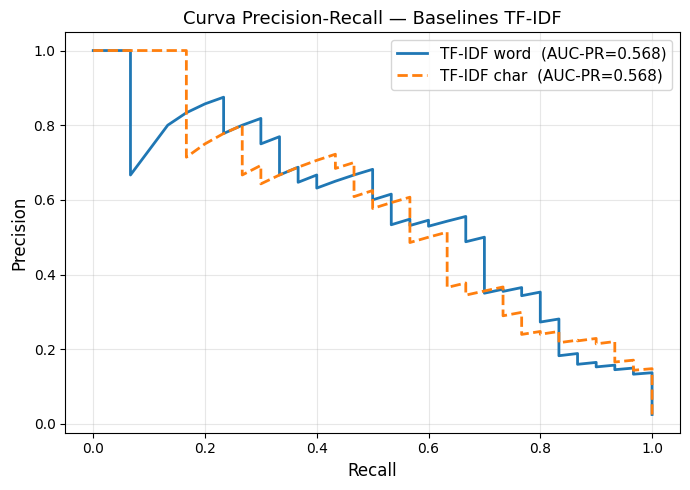

Salvo em: output/baseline_pr_curve.png


In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, auc

prec_word, rec_word, _ = precision_recall_curve(labels, sim_word)
prec_char, rec_char, _ = precision_recall_curve(labels, sim_char)

auc_word = auc(rec_word, prec_word)
auc_char = auc(rec_char, prec_char)

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(rec_word, prec_word, label=f"TF-IDF word  (AUC-PR={auc_word:.3f})", linewidth=2)
ax.plot(rec_char, prec_char, label=f"TF-IDF char  (AUC-PR={auc_char:.3f})", linewidth=2, linestyle="--")
ax.set_xlabel("Recall", fontsize=12)
ax.set_ylabel("Precision", fontsize=12)
ax.set_title("Curva Precision-Recall — Baselines TF-IDF", fontsize=13)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("output/baseline_pr_curve.png", dpi=150, bbox_inches="tight")
plt.show()
print("Salvo em: output/baseline_pr_curve.png")

## 7 — Salva CSV de predições e JSON de métricas

In [8]:
import json

df_out = df[["title_a", "title_b", "label", "item_a_normalized", "item_b_normalized",
             "exact_match_pred", "weighted_pred"]].copy()

df_out["sim_tfidf_word"]    = sim_word.round(4)
df_out["sim_tfidf_char"]    = sim_char.round(4)
df_out["pred_tfidf_word"]   = (sim_word >= thresh_word).astype(int)
df_out["pred_tfidf_char"]   = (sim_char >= thresh_char).astype(int)

out_path = Path(OUTPUT_CSV).resolve()
df_out.to_csv(out_path, index=False, encoding="utf-8-sig")
print(f"CSV salvo: {out_path}")
print(f"Colunas: {list(df_out.columns)}")

metrics_summary = {
    "tfidf_word_optimal": {"threshold": round(thresh_word, 4), **metrics_word},
    "tfidf_char_optimal": {"threshold": round(thresh_char, 4), **metrics_char},
    "tfidf_word_fixed05": {"threshold": 0.5, **metrics_word_fixed},
    "tfidf_char_fixed05": {"threshold": 0.5, **metrics_char_fixed},
    "auc_pr_word": round(auc_word, 4),
    "auc_pr_char": round(auc_char, 4),
}

json_path = Path(OUTPUT_JSON).resolve()
json_path.write_text(
    json.dumps(metrics_summary, ensure_ascii=False, indent=2) + "\n",
    encoding="utf-8",
)
print(f"Métricas salvas: {json_path}")

CSV salvo: C:\Users\nunes\invoice-data-normalizer\main_supersaurus\dados\baseline_predictions.csv
Colunas: ['title_a', 'title_b', 'label', 'item_a_normalized', 'item_b_normalized', 'exact_match_pred', 'weighted_pred', 'sim_tfidf_word', 'sim_tfidf_char', 'pred_tfidf_word', 'pred_tfidf_char']
Métricas salvas: C:\Users\nunes\invoice-data-normalizer\main_supersaurus\output\baseline_metrics.json
